1. Scenario: the scenario you found, why it fits the situations above, and the questions you want to answer (2 to 3 sentences) 

At Hospital Cempaka, the raw blood test data coming from the lab equipment is really messy, filled with missing rows and weird scientific codes like 5.40E-79. This project fits a data engineering pipeline perfectly because medical data can't be used as is it needs to be cleaned and formatted automatically before it's safe for doctors to use. By setting up this pipeline, we can instantly flag critical blood results like severe anemia or crazy high white blood cell counts so doctors can step in right away.

2. Data source : where the data came from, with the URL and how you obtained it 

3.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the raw CBC dataset
cbc_df = pd.read_csv("../CBC_L.csv")
print("Dataset shape (rows, columns):", cbc_df.shape)
cbc_df.head()

Dataset shape (rows, columns): (8727, 24)


,Unnamed: 0,SEQN,WTPH2YR,LBXWBCSI,LBXLYPCT,LBXMOPCT,LBXNEPCT,LBXEOPCT,LBXBAPCT,LBDLYMNO,...,LBXRBCSI,LBXHGB,LBXHCT,LBXMCVSI,LBXMC,LBXMCHSI,LBXRDW,LBXPLTSI,LBXMPSI,LBXNRBC
0,0,130378.0,5.604213e+04,4.7,40.8,6.8,46.1,5.2,1.2,1.9,...,5.19,15.7,45.3,87.4,34.6,30.2,12.9,259.0,7.8,0.3
1,1,130379.0,3.743571e+04,6.3,25.4,14.2,57.3,2.5,0.7,1.6,...,4.59,15.2,43.9,95.8,34.5,33.0,12.8,221.0,8.5,0.1
2,2,130380.0,8.532884e+04,5.7,29.9,5.5,58.5,5.3,0.9,1.7,...,4.86,13.8,40.1,82.5,34.4,28.3,13.3,235.0,9.1,0.1
3,3,130381.0,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,130382.0,5.963893e+04,11.4,29.9,8.3,60.1,1.2,0.6,3.4,...,4.61,12.3,36.5,79.2,33.6,26.7,14.6,342.0,7.4,0.1


In [8]:
def profile_cbc(df):
    return pd.DataFrame({
        "data_type": df.dtypes,
        "non_null_count": df.count(),
        "null_count": df.isna().sum(),
        "null_pct": (df.isna().mean() * 100).round(2),
        "unique_count": df.nunique(),
        "example_value": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None)
    })

# Run profiling on the CBC table
profile_cbc(cbc_df)

,data_type,non_null_count,null_count,null_pct,unique_count,example_value
Unnamed: 0,int64,8727,0,0.00,8727,0.00000
SEQN,float64,8727,0,0.00,8727,130378.00000
WTPH2YR,float64,8727,0,0.00,7425,56042.12941
LBXWBCSI,float64,7593,1134,12.99,145,4.70000
LBXLYPCT,float64,7582,1145,13.12,557,40.80000
LBXMOPCT,float64,7582,1145,13.12,160,6.80000
LBXNEPCT,float64,7582,1145,13.12,597,46.10000
LBXEOPCT,float64,7582,1145,13.12,159,5.20000
LBXBAPCT,float64,7582,1145,13.12,35,1.20000
LBDLYMNO,float64,7582,1145,13.12,76,1.90000


In [12]:
# Check detection limit values (numbers less than 1e-10)
validity_limit_code_count = (cbc_df.drop(columns=["SEQN", "Unnamed: 0"], errors="ignore") < 1e-10).sum().sum()

quality_checks = {
    # 1. Completeness Dimension
    "Completeness: Missing Hemoglobin (LBXHGB)": cbc_df["LBXHGB"].isna().sum(),
    "Completeness: Missing WBC (LBXWBCSI)": cbc_df["LBXWBCSI"].isna().sum(),
    "Completeness: Missing Platelet (LBXPLTSI)": cbc_df["LBXPLTSI"].isna().sum(),
    "Completeness: Missing Hematocrit (LBXHCT)": cbc_df["LBXHCT"].isna().sum(),
    
    # 2. Validity & Data Type Issues
    "Validity: Scientific Detection Limit Codes (< 1e-10)": validity_limit_code_count,
    "Validity: SEQN float type instead of integer": (cbc_df["SEQN"].dtype == "float64"),
    
    # 3. Redundancy / Structure
    "Redundancy: Unnecessary index column (Unnamed: 0)": ("Unnamed: 0" in cbc_df.columns),
    
    # 4. Outliers (Medical Boundaries)
    "Outliers: High WBC / Leukocytosis (> 11.0 x10^3/uL)": (cbc_df["LBXWBCSI"] > 11.0).sum(),
    "Outliers: Low WBC / Leukopenia (< 4.0 x10^3/uL)": (cbc_df["LBXWBCSI"] < 4.0).sum(),
    "Outliers: Low HGB / Anemia (< 10.0 g/dL)": (cbc_df["LBXHGB"] < 10.0).sum()
}

pd.Series(quality_checks).to_frame(name="issue_count")

,issue_count
Completeness: Missing Hemoglobin (LBXHGB),1134
Completeness: Missing WBC (LBXWBCSI),1134
Completeness: Missing Platelet (LBXPLTSI),1134
Completeness: Missing Hematocrit (LBXHCT),1134
Validity: Scientific Detection Limit Codes (< 1e-10),8588
Validity: SEQN float type instead of integer,True
Redundancy: Unnecessary index column (Unnamed: 0),True
Outliers: High WBC / Leukocytosis (> 11.0 x10^3/uL),299
Outliers: Low WBC / Leukopenia (< 4.0 x10^3/uL),236
Outliers: Low HGB / Anemia (< 10.0 g/dL),89


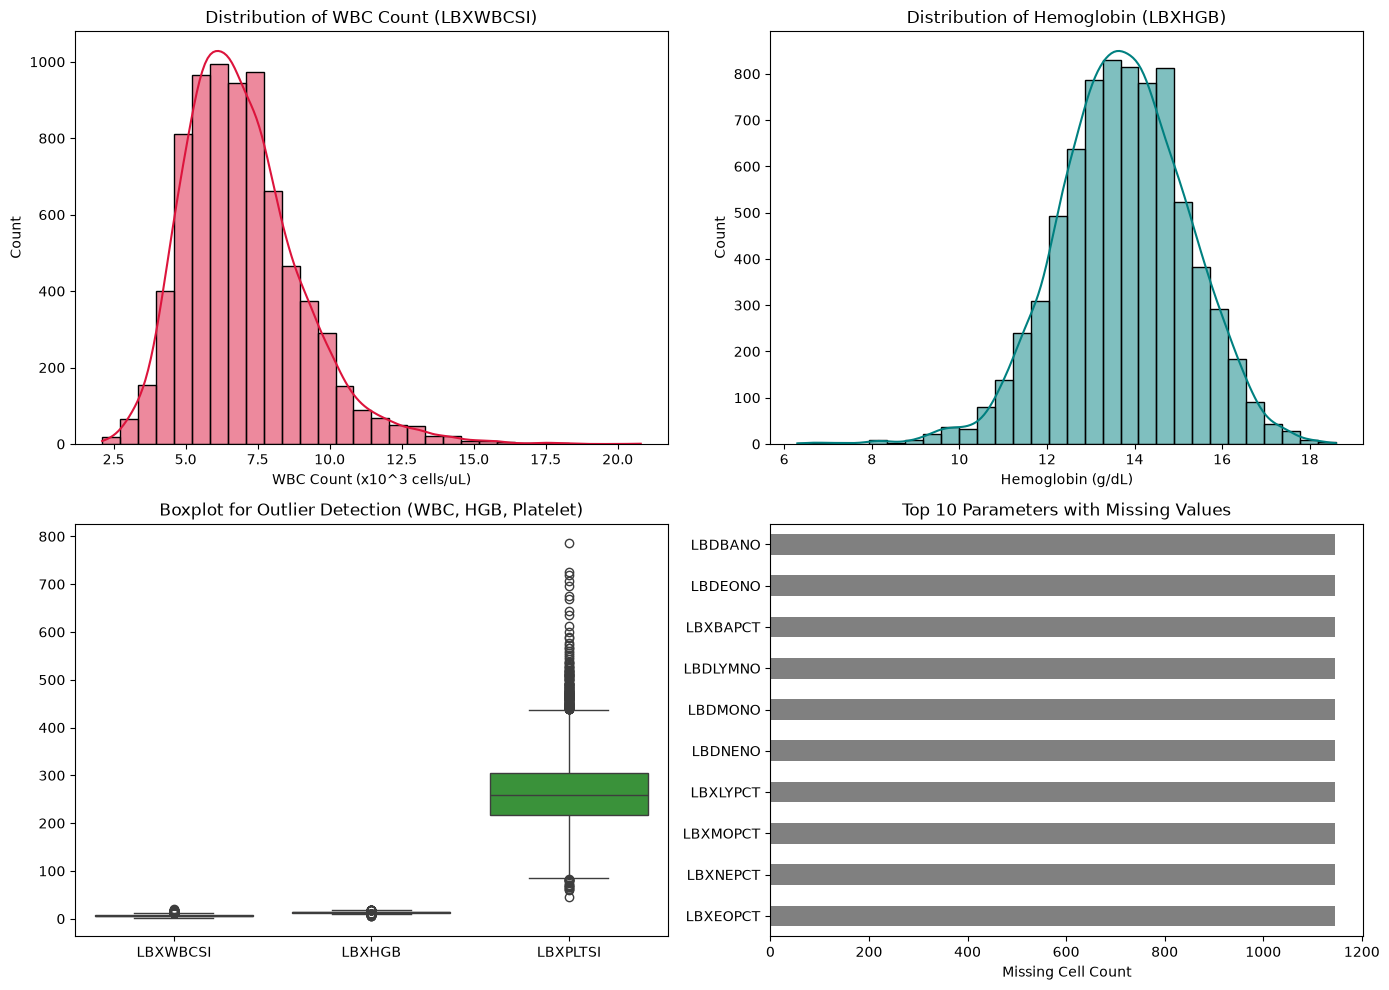

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Chart 1: Distribution of White Blood Cell Count (LBXWBCSI)
sns.histplot(cbc_df["LBXWBCSI"].dropna(), bins=30, kde=True, ax=axes[0, 0], color="crimson")
axes[0, 0].set_title("Distribution of WBC Count (LBXWBCSI)")
axes[0, 0].set_xlabel("WBC Count (x10^3 cells/uL)")

# Chart 2: Distribution of Hemoglobin (LBXHGB)
sns.histplot(cbc_df["LBXHGB"].dropna(), bins=30, kde=True, ax=axes[0, 1], color="teal")
axes[0, 1].set_title("Distribution of Hemoglobin (LBXHGB)")
axes[0, 1].set_xlabel("Hemoglobin (g/dL)")

# Chart 3: Detection of Outliers in Key Blood Parameters (Boxplot)
sns.boxplot(data=cbc_df[["LBXWBCSI", "LBXHGB", "LBXPLTSI"]].dropna(), ax=axes[1, 0])
axes[1, 0].set_title("Boxplot for Outlier Detection (WBC, HGB, Platelet)")

# Chart 4: Missing Values Count per Blood Test Parameter
missing_counts = cbc_df.isna().sum().sort_values(ascending=False).head(10)
missing_counts.plot(kind="barh", ax=axes[1, 1], color="gray")
axes[1, 1].set_title("Top 10 Parameters with Missing Values")
axes[1, 1].set_xlabel("Missing Cell Count")

plt.tight_layout()
plt.show()

## Hospital Cempaka - CBC Data Quality Report 

### Data Quality Issues Summary Table

| Dimension | Table.column | Quality Check / Issue Description | Issues Found (Exact Count) | Fix Planned for Lab 5 / Silver Layer |
| :--- | :--- | :--- | :--- | :--- |
| **Completeness** | `CBC_L.LBXHGB` | Missing Hemoglobin values | **1,134 rows** | **Drop rows** missing critical primary diagnostic values. Medical lab data will not be imputed to avoid clinical inaccuracy. |
| **Completeness** | `CBC_L.LBXWBCSI` | Missing White Blood Cell (WBC) count[cite: 8] | **1,134 rows**[cite: 8] | **Drop rows** missing critical blood parameters. |
| **Completeness** | `CBC_L.LBXPLTSI` | Missing Platelet count[cite: 8] | **1,134 rows**[cite: 8] | **Drop rows** missing critical blood parameters. |
| **Completeness** | `CBC_L.LBXHCT` | Missing Hematocrit values[cite: 8] | **1,134 rows**[cite: 8] | **Drop rows** missing critical blood parameters. |
| **Validity** | Multiple CBC columns | Scientific detection limit codes (`< 1e-10` / `5.40E-79`)[cite: 1, 8] | **8,588 cells**[cite: 8] | **Replace** detection limit values with `0.0` or threshold floor, then cast affected columns properly. |
| **Consistency** | `CBC_L.SEQN` | Patient ID stored in `float64` format instead of integer[cite: 5, 8] | **True / Present** (All rows)[cite: 5, 8] | **Cast column** `SEQN` to integer (`int64`) or string format during Silver ingestion. |
| **Redundancy** | `CBC_L.Unnamed: 0` | Unnecessary index column generated during export[cite: 4, 8] | **True / Present** (8,727 rows)[cite: 4, 8] | **Drop column** `Unnamed: 0` during Silver layer transformation. |
| **Accuracy / Outlier** | `CBC_L.LBXWBCSI` | High WBC count (> 11.0 x10^3/uL - High infection risk)[cite: 8] | **299 rows**[cite: 8] | **Keep & Flag** as critical cases for ML physician alert pipeline. |
| **Accuracy / Outlier** | `CBC_L.LBXWBCSI` | Low WBC count (< 4.0 x10^3/uL - Leukopenia)[cite: 8] | **236 rows**[cite: 8] | **Keep & Flag** for clinical evaluation. |
| **Accuracy / Outlier** | `CBC_L.LBXHGB` | Low Hemoglobin (< 10.0 g/dL - Severe Anemia indicator)[cite: 8] | **89 rows**[cite: 8] | **Keep & Tag** for urgent notification. |

---

### Data Profiling & Issue Handling Strategy

1. **Missing Values Handling:** 
   Profiling revealed a total of **1,134 rows** (~13% of records) systematically missing key pathology parameters (WBC, HGB, Platelet, HCT)[cite: 5, 8]. In the Silver Layer (Lab 5), these missing rows will be **dropped** instead of imputed. Imputing values in medical diagnostics creates artificial measurements, which violates clinical safety.

2. **Validity & Format Correction:** 
   We detected **8,588 cells** containing scientific notation values (`< 1e-10` representing `5.40E-79` below detection limit)[cite: 1, 8]. In Lab 5, these values will be **replaced with 0.0** or mapped to the minimum detectable limit, and columns will be standardized to `float64`. Additionally, the redundant index column `Unnamed: 0` will be dropped[cite: 4, 8].

3. **Clinical Outlier Strategy:** 
   Statistical profiling identified **299 high WBC**, **236 low WBC**, and **89 low HGB critical outlier cases**[cite: 8]. Standard outlier removal (such as capping via IQR) will **NOT** be applied. In clinical data, extreme values represent genuine emergency medical conditions (such as severe infection or leukopenia). These outliers are retained and will be tagged with urgency flags to enable effective prediction by the downstream ML model.

4.

5.

6.